In [1]:
import pandas as pd

# Carregar os dados (ajustado à tua pasta data/raw)
df = pd.read_csv('/Users/joelfigueiras/Desktop/Project_Ciber_ML/data/raw/ml_features_and_labels.csv')

# Verificar se carregou bem
print(df.shape) 
print(df.head())

(40010, 36)
   e2c_total_bytes  e4_entropy_h  e5_entropy_c  e6_time_char  \
0             8182        4.7889        5.8077          2.45   
1             8126        5.0000        5.8367          2.44   
2             8272        4.7889        5.9056          2.73   
3             8272        4.8125        5.9056          2.31   
4             8272        4.8125        5.8367          4.45   

   e6b_flow_duration_ms  e2_client_size  e2_client_record_len  \
0            149.827957            32.0                   285   
1            231.020927            32.0                   285   
2            292.967796            32.0                   285   
3            156.050205            32.0                   285   
4            193.972111            32.0                   285   

   e2_server_record_len  e3_cert_parsed  e1_alg_suite_Unknown(0x11eb)  ...  \
0                5316.0           False                         False  ...   
1                5316.0           False                 

In [2]:
# 1. Verificar se há valores vazios (Missing Values)
print("Valores em falta por coluna:")
print(df.isnull().sum())

# 2. Ver a distribuição das labels (Normal vs Ataque)
# Isto responde à parte de "Balanceamento" do trabalho
print("\nContagem de Labels (0 = Normal, 1 = Anomalia):")
print(df['label'].value_counts())

Valores em falta por coluna:
e2c_total_bytes                         0
e4_entropy_h                            0
e5_entropy_c                         2510
e6_time_char                         1000
e6b_flow_duration_ms                    0
e2_client_size                        500
e2_client_record_len                    0
e2_server_record_len                 1000
e3_cert_parsed                          0
e1_alg_suite_Unknown(0x11eb)            0
e1_alg_suite_Unknown(0x11ec)            0
e1_alg_suite_mlkem1024                  0
e1_alg_suite_mlkem768                   0
e1_alg_suite_x25519                     0
e1_alg_suite_nan                        0
e8_proto_context_TLSv1.2_or_older       0
e8_proto_context_TLSv1.3                0
e9_conn_outcome_Failure                 0
e9_conn_outcome_Incomplete              0
e9_conn_outcome_Success                 0
e3_sig_alg_Unknown(0x0028)              0
e3_sig_alg_nan                          0
e1b_tls_version_SSL3.0                  0
e1b_t

In [3]:
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# 1. Definir os dados de teste (usando o df original que tem nulos)
# Selecionamos apenas as colunas numéricas
X_teste_imputacao = df.select_dtypes(include=[np.number]).drop(columns=['label'], errors='ignore')
y_teste_imputacao = df['label']

estrategias = ['mean', 'median', 'constant']
resultados = {}

for est in estrategias:
    # Aplicar a técnica de preenchimento
    imputer = SimpleImputer(strategy=est)
    X_imputed = imputer.fit_transform(X_teste_imputacao)
    
    # Testar com Cross-Validation
    model_test = RandomForestClassifier(n_estimators=50, random_state=42)
    # cv=3 faz o teste 3 vezes com divisões diferentes para garantir que o resultado é sólido
    score = cross_val_score(model_test, X_imputed, y_teste_imputacao, cv=3, scoring='f1')
    resultados[est] = score.mean()

print("\n--- RESULTADO DA PROVA ---")
for est, valor in resultados.items():
    print(f"Estratégia {est}: F1-Score Médio = {valor:.4f}")


--- RESULTADO DA PROVA ---
Estratégia mean: F1-Score Médio = 0.3865
Estratégia median: F1-Score Médio = 0.3991
Estratégia constant: F1-Score Médio = 0.4145


In [4]:
# Preencher valores em falta com a média de cada coluna
# Isso garante que não perdemos as 40.010 linhas
df_clean = df.copy()
df_clean['e5_entropy_c'] = df_clean['e5_entropy_c'].fillna(df_clean['e5_entropy_c'].fillna(0))
df_clean['e6_time_char'] = df_clean['e6_time_char'].fillna(df_clean['e6_time_char'].fillna(0))
df_clean['e2_client_size'] = df_clean['e2_client_size'].fillna(df_clean['e2_client_size'].fillna(0))
df_clean['e2_server_record_len'] = df_clean['e2_server_record_len'].fillna(df_clean['e2_server_record_len'].fillna(0))

# Verificar se ainda há nulos
print("Nulos após limpeza:", df_clean.isnull().sum().sum())

Nulos após limpeza: 0


In [5]:
from sklearn.preprocessing import StandardScaler

# 1. Selecionar apenas colunas numéricas e remover a label (K-means não usa labels!)
# Também removemos IDs ou colunas de texto se existirem
X = df_clean.select_dtypes(include=['float64', 'int64']).drop(columns=['label'], errors='ignore')

# 2. Normalizar os dados
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dados normalizados com sucesso. Formato:", X_scaled.shape)

Dados normalizados com sucesso. Formato: (40010, 8)


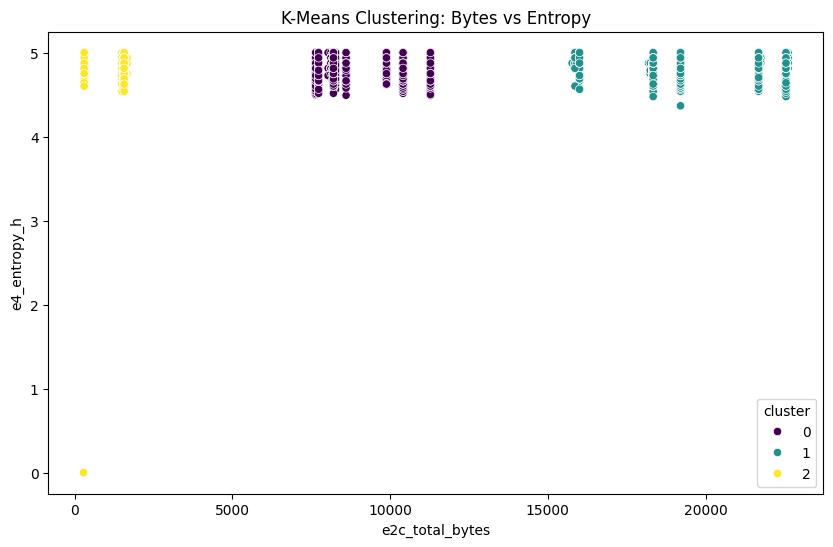

In [8]:
from sklearn.cluster import KMeans

# 1. Definir e treinar o K-Means (ajusta o n_clusters se necessário)
kmeans = KMeans(n_clusters=3, random_state=42)

# 2. CRIAR a coluna que está a faltar no df_clean
# Aqui usamos apenas as colunas numéricas que o modelo aceita
X_clustering = df_clean.select_dtypes(include=[np.number]).drop(columns=['label'], errors='ignore')
df_clean['cluster'] = kmeans.fit_predict(X_clustering)

# 3. Agora o gráfico já vai encontrar o 'hue=cluster'
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='e2c_total_bytes', y='e4_entropy_h', hue='cluster', palette='viridis')
plt.title('K-Means Clustering: Bytes vs Entropy')
plt.show()

In [10]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# 1. Preparar os dados finais (remover o que não é número e a label)
X_final = df_clean.select_dtypes(include=['float64', 'int64']).drop(columns=['label', 'cluster'], errors='ignore')
y_final = df_clean['label']

# 2. Dividir em Treino e Teste (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(X_final, y_final, test_size=0.2, random_state=42)

# 3. Aplicar o SMOTE apenas no conjunto de TREINO
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)

print(f"Antes do SMOTE: {y_train.value_counts().to_dict()}")
print(f"Depois do SMOTE: {y_res.value_counts().to_dict()}")

Antes do SMOTE: {0: 28029, 1: 3979}
Depois do SMOTE: {0: 28029, 1: 28029}


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
import time

# 1. Definir os modelos
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

# 2. Treinar e Avaliar
for name, model in models.items():
    start_time = time.time()
    
    # Treinar com os dados equilibrados (X_res, y_res)
    model.fit(X_res, y_res)
    
    # Prever nos dados de teste REAIS (X_test)
    y_pred = model.predict(X_test)
    
    end_time = time.time()
    
    print(f"\n--- {name} ---")
    print(f"Tempo de execução: {end_time - start_time:.2f} segundos")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred))

/Users/joelfigueiras/Desktop/Project_Ciber_ML/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



--- Logistic Regression ---
Tempo de execução: 1.67 segundos
Accuracy: 0.9409
              precision    recall  f1-score   support

           0       0.97      0.96      0.97      6971
           1       0.76      0.79      0.78      1031

    accuracy                           0.94      8002
   macro avg       0.86      0.88      0.87      8002
weighted avg       0.94      0.94      0.94      8002


--- Random Forest ---
Tempo de execução: 2.32 segundos
Accuracy: 0.9620
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      6971
           1       0.89      0.81      0.85      1031

    accuracy                           0.96      8002
   macro avg       0.93      0.90      0.91      8002
weighted avg       0.96      0.96      0.96      8002



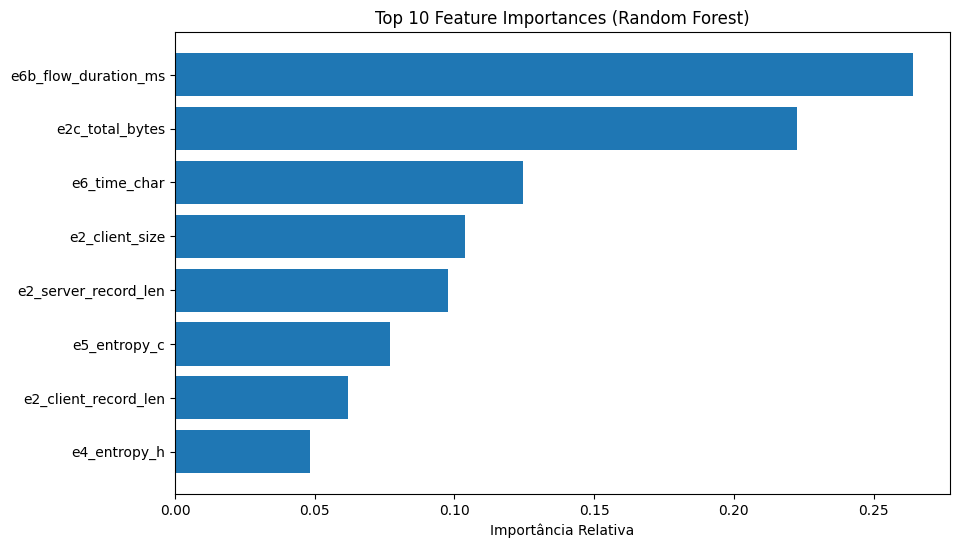

In [12]:
import numpy as np

# Extrair a importância das colunas do Random Forest
importances = models["Random Forest"].feature_importances_
indices = np.argsort(importances)[-10:]  # As 10 mais importantes

plt.figure(figsize=(10, 6))
plt.title('Top 10 Feature Importances (Random Forest)')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [X_final.columns[i] for i in indices])
plt.xlabel('Importância Relativa')
plt.show()

<Figure size 800x600 with 0 Axes>

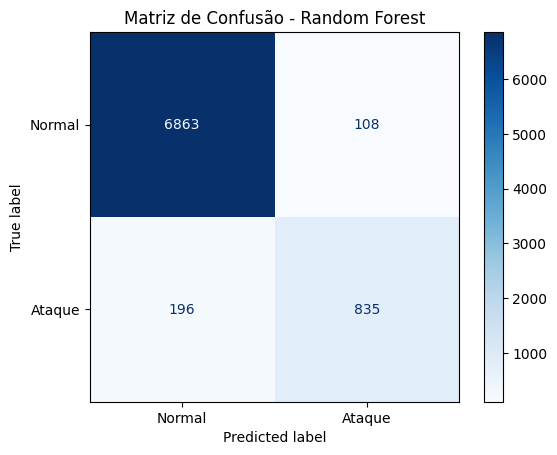

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Gerar a matriz para o Random Forest (o teu melhor modelo)
cm = confusion_matrix(y_test, models["Random Forest"].predict(X_test))

# Desenhar
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Ataque'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusão - Random Forest')
plt.show()